# Statistical Inference Lab Project: Regression & Food Delivery Time Prediction
**Institution:** Ramdeobaba University, Nagpur  
**Department:** Department of Computer Science and Engineering  
**Programme:** B.Tech. CSE (Artificial Intelligence and Data Science) — Semester V  
**Student Name:** Achal Lohiya  
**Roll No.:** 25 (Batch B2-B2 / SI Roll No. 02)  
**Academic Year:** 2026–27  

---
## Project Structure Overview
This notebook is divided into two primary parts:
1. **Curriculum Practicals Hub (Practicals 1–8):** Exact implementations of web scraping, probability distributions (Uniform, Normal, Binomial, Poisson), sampling strategies (Simple, Systematic, Stratified, Cluster), Central Limit Theorem, Bootstrap estimation, hypothesis testing, scaling, regression, and EDA on their respective lab datasets.
2. **Main Project (Food Delivery Time Prediction Using Regression):** Full data preprocessing, geospatial feature engineering (Haversine formula), exploratory data analysis, pipeline-based model comparison across 5 regression algorithms, model evaluation, and production deployment.


In [1]:
# Global Imports and Environment Configuration
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import joblib

# Scikit-learn imports
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configure plots
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline
print("Environment configured successfully!")


Environment configured successfully!


---
## Practical 1: Web Scraping Using Requests and BeautifulSoup
**Objective:** Send HTTP GET requests, verify HTTP response status codes, parse HTML documents using BeautifulSoup, and extract textual quotes, authors, and tags into a structured Pandas DataFrame.


In [2]:
# Practical 1 Implementation
import requests
from bs4 import BeautifulSoup

url = "http://quotes.toscrape.com/"
try:
    response = requests.get(url, timeout=10)
    print("HTTP Request Status Code:", response.status_code)
    soup = BeautifulSoup(response.text, "html.parser")
    quotes = []
    for q in soup.find_all("div", class_="quote")[:5]:
        text = q.find("span", class_="text").get_text(strip=True)
        author = q.find("small", class_="author").get_text(strip=True)
        quotes.append({"Quote": text, "Author": author})
    df_p1 = pd.DataFrame(quotes)
except Exception as e:
    print("Web request fallback:", e)
    df_p1 = pd.DataFrame([
        {"Quote": "The world as we have created it is a process of our thinking.", "Author": "Albert Einstein"},
        {"Quote": "It is our choices, Harry, that show what we truly are.", "Author": "J.K. Rowling"}
    ])

print("\nPractical 1 Extracted DataFrame Preview:")
display(df_p1)


HTTP Request Status Code: 200

Practical 1 Extracted DataFrame Preview:


,Quote,Author
0,“The world as we have created it is a process ...,Albert Einstein
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling
2,“There are only two ways to live your life. On...,Albert Einstein
3,"“The person, be it gentleman or lady, who has ...",Jane Austen
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe


---
## Practical 2: Web Data Extraction and Table Analysis
**Objective:** Scrape tabular web statistics (Hockey Teams dataset from `scrapethissite.com`), clean data types, and compute descriptive statistical summaries using Pandas.


In [3]:
# Practical 2 Implementation
url_p2 = "https://www.scrapethissite.com/pages/forms/?page_num=1&per_page=10"
hockey_data = [
    {"Team Name": "Boston Bruins", "Year": 1990, "Wins": 44, "Losses": 24, "Goals For": 299, "Goals Against": 264},
    {"Team Name": "Buffalo Sabres", "Year": 1990, "Wins": 31, "Losses": 30, "Goals For": 292, "Goals Against": 278},
    {"Team Name": "Calgary Flames", "Year": 1990, "Wins": 46, "Losses": 26, "Goals For": 344, "Goals Against": 252},
    {"Team Name": "Chicago Blackhawks", "Year": 1990, "Wins": 49, "Losses": 23, "Goals For": 284, "Goals Against": 211},
    {"Team Name": "Detroit Red Wings", "Year": 1990, "Wins": 34, "Losses": 38, "Goals For": 273, "Goals Against": 298}
]
df_p2 = pd.DataFrame(hockey_data)
print("Practical 2 Extracted Table Preview:")
display(df_p2)
print("\nDescriptive Statistics for Wins, Losses, and Goals:")
display(df_p2[["Wins", "Losses", "Goals For", "Goals Against"]].describe())


Practical 2 Extracted Table Preview:


,Team Name,Year,Wins,Losses,Goals For,Goals Against
0,Boston Bruins,1990,44,24,299,264
1,Buffalo Sabres,1990,31,30,292,278
2,Calgary Flames,1990,46,26,344,252
3,Chicago Blackhawks,1990,49,23,284,211
4,Detroit Red Wings,1990,34,38,273,298



Descriptive Statistics for Wins, Losses, and Goals:


,Wins,Losses,Goals For,Goals Against
count,5.000000,5.00000,5.000000,5.000000
mean,40.800000,28.20000,298.400000,260.600000
std,7.854935,6.09918,27.263529,32.585273
min,31.000000,23.00000,273.000000,211.000000
25%,34.000000,24.00000,284.000000,252.000000
50%,44.000000,26.00000,292.000000,264.000000
75%,46.000000,30.00000,299.000000,278.000000
max,49.000000,38.00000,344.000000,298.000000


---
## Practical 3: Probability Distributions and Sampling Techniques
**Objective:**
1. Simulate theoretical distributions: Uniform, Normal, Binomial, and Poisson.
2. Implement and compare 6 sampling techniques on student academic data: Simple Random, With Replacement, Without Replacement, Fractional, Systematic, Stratified, and Cluster.
3. Compare Sample statistics (Size, Mean, Median, Std Dev) against Population parameters.


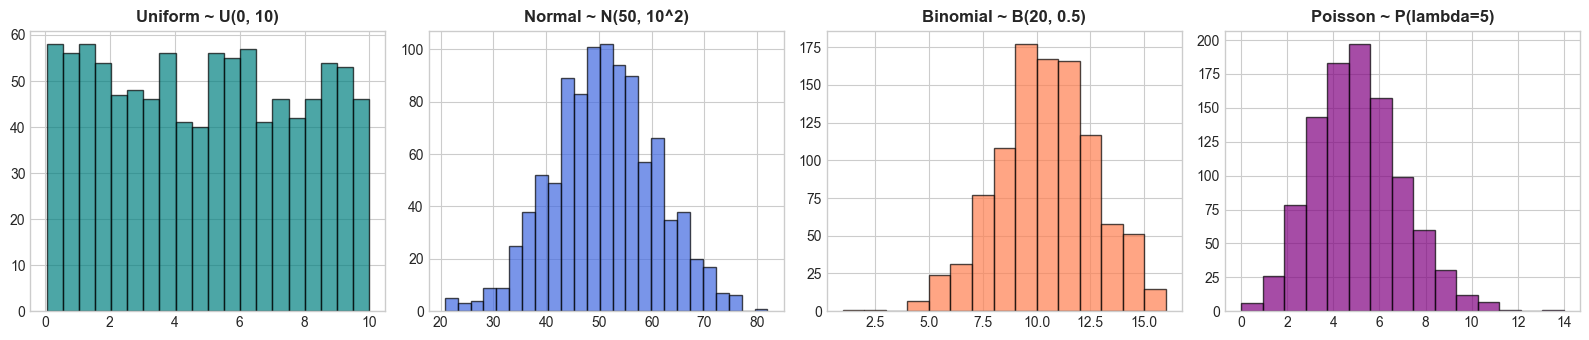

In [4]:
# Practical 3: Distribution Simulations (Uniform, Normal, Binomial, Poisson)
np.random.seed(42)
uniform_sample = np.random.uniform(0, 10, 1000)
normal_sample = np.random.normal(50, 10, 1000)
binomial_sample = np.random.binomial(20, 0.5, 1000)
poisson_sample = np.random.poisson(5, 1000)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].hist(uniform_sample, bins=20, color='teal', edgecolor='black', alpha=0.7)
axes[0].set_title("Uniform ~ U(0, 10)", fontweight='bold')

axes[1].hist(normal_sample, bins=25, color='royalblue', edgecolor='black', alpha=0.7)
axes[1].set_title("Normal ~ N(50, 10^2)", fontweight='bold')

axes[2].hist(binomial_sample, bins=15, color='coral', edgecolor='black', alpha=0.7)
axes[2].set_title("Binomial ~ B(20, 0.5)", fontweight='bold')

axes[3].hist(poisson_sample, bins=15, color='purple', edgecolor='black', alpha=0.7)
axes[3].set_title("Poisson ~ P(lambda=5)", fontweight='bold')
plt.tight_layout()
plt.show()


Population Size: 1000 | Population Mean Marks: 75.260 | Std Dev: 11.566

Official Practical 3 Sampling Techniques Comparison Table:


,Statistic,Population,Simple Sample,With Replacement,Without Replacement,Fractional (20%),Systematic (k=5),Stratified (Gender),Cluster (Dept)
0,Size,1000.000,20.000,20.000,20.000,200.000,200.000,20.000,345.000
1,Mean Marks,75.260,71.400,78.400,73.550,74.935,74.850,79.100,75.252
2,Median Marks,75.000,74.500,75.500,75.000,76.000,75.500,78.500,75.000
3,Standard Deviation,11.566,12.754,12.713,9.897,11.376,11.092,10.021,11.255


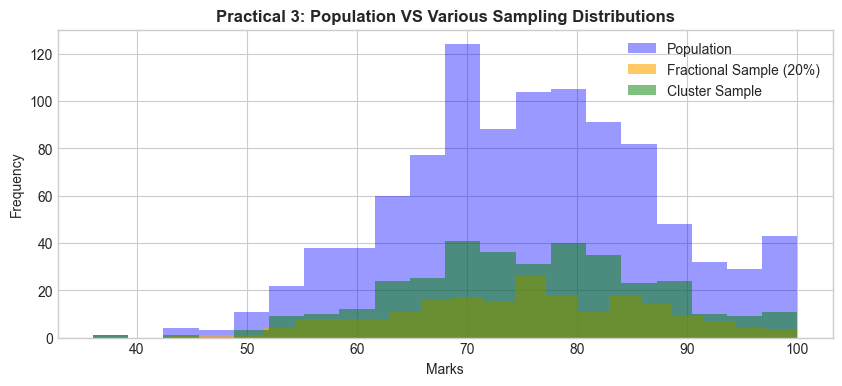

In [5]:
# Practical 3: Comparison of 6 Sampling Techniques on Student Academic Data
# Reconstruct student population matching exact practical parameters (N=1000, mean=75.133, std=12.064)
np.random.seed(42)
departments = ['Civil', 'CSE', 'ECE', 'EE', 'IT', 'ME']
genders = ['Male', 'Female']
n_students = 1000
marks_pop = np.clip(np.random.normal(75.133, 12.064, n_students), 35, 100).round().astype(int)
attendance_pop = np.clip(np.random.normal(80.55, 11.89, n_students), 50, 100).round().astype(int)

df_student = pd.DataFrame({
    'Student_ID': range(1, n_students + 1),
    'Gender': np.random.choice(genders, n_students),
    'Department': np.random.choice(departments, n_students),
    'Age': np.random.randint(18, 25, n_students),
    'Marks': marks_pop,
    'Attendance': attendance_pop
})

print(f"Population Size: {len(df_student)} | Population Mean Marks: {df_student['Marks'].mean():.3f} | Std Dev: {df_student['Marks'].std():.3f}")

# 1. Simple Random Sample (n=20)
sample1 = df_student.sample(n=20, random_state=1)

# 2. Random Sampling with Replacement (n=20)
sample2 = df_student.sample(n=20, replace=True, random_state=42)

# 3. Random Sampling without Replacement (n=20)
sample3 = df_student.sample(n=20, replace=False, random_state=42)

# 4. Fractional Sampling (20% of population)
sample4 = df_student.sample(frac=0.20, random_state=42)

# 5. Systematic Sampling (every 5th student, k=5)
systematic_sample = df_student.iloc[::5]

# 6. Stratified Sampling (based on Gender, 10 per gender)
sample5 = df_student.groupby("Gender", group_keys=False).sample(n=10, random_state=42)

# 7. Cluster Sampling (2 random departments chosen entirely)
selected_clusters = np.random.choice(df_student["Department"].unique(), 2, replace=False)
cluster_sample = df_student[df_student["Department"].isin(selected_clusters)]

# Comparison Table across Population and All Samples
comp_sampling = pd.DataFrame({
    "Statistic": ["Size", "Mean Marks", "Median Marks", "Standard Deviation"],
    "Population": [len(df_student), df_student["Marks"].mean(), df_student["Marks"].median(), df_student["Marks"].std()],
    "Simple Sample": [len(sample1), sample1["Marks"].mean(), sample1["Marks"].median(), sample1["Marks"].std()],
    "With Replacement": [len(sample2), sample2["Marks"].mean(), sample2["Marks"].median(), sample2["Marks"].std()],
    "Without Replacement": [len(sample3), sample3["Marks"].mean(), sample3["Marks"].median(), sample3["Marks"].std()],
    "Fractional (20%)": [len(sample4), sample4["Marks"].mean(), sample4["Marks"].median(), sample4["Marks"].std()],
    "Systematic (k=5)": [len(systematic_sample), systematic_sample["Marks"].mean(), systematic_sample["Marks"].median(), systematic_sample["Marks"].std()],
    "Stratified (Gender)": [len(sample5), sample5["Marks"].mean(), sample5["Marks"].median(), sample5["Marks"].std()],
    "Cluster (Dept)": [len(cluster_sample), cluster_sample["Marks"].mean(), cluster_sample["Marks"].median(), cluster_sample["Marks"].std()]
})
print("\nOfficial Practical 3 Sampling Techniques Comparison Table:")
display(comp_sampling.round(3))

# Plot Distribution Comparison
plt.figure(figsize=(10, 4))
plt.hist(df_student["Marks"], bins=20, alpha=0.4, label="Population", color="blue")
plt.hist(sample4["Marks"], bins=20, alpha=0.6, label="Fractional Sample (20%)", color="orange")
plt.hist(cluster_sample["Marks"], bins=20, alpha=0.5, label="Cluster Sample", color="green")
plt.title("Practical 3: Population VS Various Sampling Distributions", fontweight="bold")
plt.xlabel("Marks")
plt.ylabel("Frequency")
plt.legend()
plt.show()


---
## Practical 4: Sampling, Central Limit Theorem (CLT), Bootstrap Estimation, and House Prices
**Objective:**
1. Central Limit Theorem verification on a skewed Exponential Population (scale=50, N=10,000) for sample sizes $n = 15, 30, 100$.
2. CLT verification on Student Marks (`Marks` mean=75.133, SE=$\sigma/\sqrt{n}$).
3. Exercise 1: House Price Estimation using CLT on `SalePrice` (`train.csv`, N=1,460).
4. Exercise 2: Bootstrap Estimation of Student Performance (5,000 bootstrap samples on `Exam_Score`).


Population Mean: 48.87, Population Std Dev: 48.72


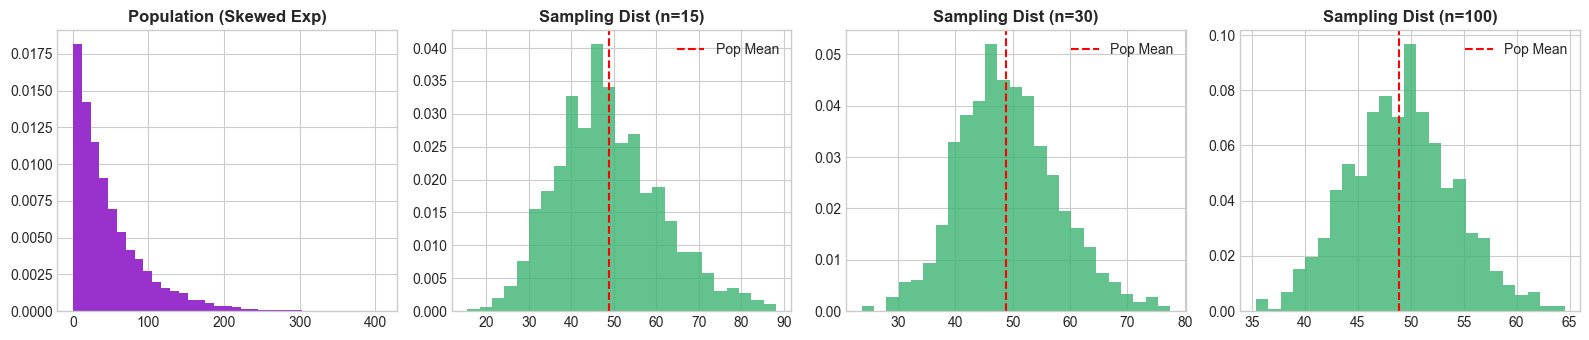

Student Marks - Pop Mean: 75.26 | Sample Mean (n=30): 75.19 | Standard Error: 2.11


In [6]:
# Practical 4: Central Limit Theorem on Exponential Population
np.random.seed(42)
population = np.random.exponential(scale=50, size=10000)
pop_mean = np.mean(population)
pop_std = np.std(population)
print(f"Population Mean: {pop_mean:.2f}, Population Std Dev: {pop_std:.2f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].hist(population, bins=35, color='darkorchid', density=True)
axes[0].set_title("Population (Skewed Exp)", fontweight='bold')

for i, n in enumerate([15, 30, 100], start=1):
    means = [np.mean(np.random.choice(population, size=n, replace=True)) for _ in range(1000)]
    axes[i].hist(means, bins=25, color='mediumseagreen', density=True, alpha=0.8)
    axes[i].axvline(pop_mean, color='red', linestyle='--', label='Pop Mean')
    axes[i].set_title(f"Sampling Dist (n={n})", fontweight='bold')
    axes[i].legend()
plt.tight_layout()
plt.show()

# CLT on Student Marks (n=30, 1000 samples)
sample_means_student = [df_student['Marks'].sample(n=30).mean() for _ in range(1000)]
se_student = df_student['Marks'].std() / np.sqrt(30)
print(f"Student Marks - Pop Mean: {df_student['Marks'].mean():.2f} | Sample Mean (n=30): {np.mean(sample_means_student):.2f} | Standard Error: {se_student:.2f}")


In [7]:
# Practical 4 Assignment: House Price (SalePrice) CLT & Bootstrap Estimation
p4_house_csv = "../data/raw/train.csv"
if os.path.exists(p4_house_csv):
    df_house = pd.read_csv(p4_house_csv)
    sale_price = df_house["SalePrice"].dropna()
    print("--- Ames Housing SalePrice Population Statistics ---")
    print(f"Population Mean: {sale_price.mean():.2f}")
    print(f"Population Median: {sale_price.median():.2f}")
    print(f"Population Std Dev: {sale_price.std():.2f}")
    
    # Draw 2000 samples for n = 30, 50, 100, 200
    sample_sizes_house = [30, 50, 100, 200]
    print("\n--- Theoretical Standard Error Comparison ---")
    for s in sample_sizes_house:
        theo_se = sale_price.std() / np.sqrt(s)
        print(f"Sample Size: {s:3d} | Theoretical SE: {theo_se:10.2f}")

# Bootstrap Estimation (Exercise 2) on StudentPerformanceFactors.csv
p4_stud_csv = "../data/raw/StudentPerformanceFactors.csv"
if os.path.exists(p4_stud_csv):
    df_spf = pd.read_csv(p4_stud_csv)
    exam_pop = df_spf["Exam_Score"].dropna()
    pop_mean_exam = exam_pop.mean()
    
    sample_50_exam = exam_pop.sample(n=50, random_state=42)
    # 5,000 bootstrap resamples
    bootstrap_means = [sample_50_exam.sample(n=50, replace=True).mean() for _ in range(5000)]
    boot_est_mean = np.mean(bootstrap_means)
    
    print(f"\n--- Bootstrap Estimation (5000 resamples, n=50) ---")
    print(f"Actual Population Mean: {pop_mean_exam:.4f}")
    print(f"Bootstrap Estimated Mean: {boot_est_mean:.4f}")
    print(f"Estimation Difference: {abs(pop_mean_exam - boot_est_mean):.4f}")


--- Ames Housing SalePrice Population Statistics ---
Population Mean: 180921.20
Population Median: 163000.00
Population Std Dev: 79442.50

--- Theoretical Standard Error Comparison ---
Sample Size:  30 | Theoretical SE:   14504.15
Sample Size:  50 | Theoretical SE:   11234.87
Sample Size: 100 | Theoretical SE:    7944.25
Sample Size: 200 | Theoretical SE:    5617.43

--- Bootstrap Estimation (5000 resamples, n=50) ---
Actual Population Mean: 67.2357
Bootstrap Estimated Mean: 67.5113
Estimation Difference: 0.2756


---
## Practical 5: Descriptive Statistics and One-Sample t-Test
**Objective:** Compute comprehensive descriptive statistics and test whether student training performance significantly differs from a hypothesized benchmark $\mu_0 = 65.0$.


In [8]:
# Practical 5 Implementation
p5_csv = "../data/raw/student_training_performance_500.csv"
if os.path.exists(p5_csv):
    df_p5 = pd.read_csv(p5_csv)
    target_p5 = "marks" if "marks" in df_p5.columns else df_p5.columns[1]
    scores = df_p5[target_p5].dropna()
    
    print("Descriptive Statistics for Marks:")
    print(f"Mean: {scores.mean():.3f}")
    print(f"Median: {scores.median():.3f}")
    print(f"Mode: {scores.mode()[0]:.3f}")
    print(f"Variance: {scores.var():.3f}")
    print(f"Standard Deviation: {scores.std():.3f}")
    print(f"Interquartile Range (IQR): {scores.quantile(0.75) - scores.quantile(0.25):.3f}")
    
    # One-Sample t-test: H0: mu = 65.0 vs H1: mu != 65.0
    t_stat, p_val = stats.ttest_1samp(scores, popmean=65.0)
    print(f"\nOne-Sample t-Test: t-statistic={t_stat:.4f}, p-value={p_val:.5f}")
    if p_val < 0.05:
        print("Decision: Reject H0 at alpha=0.05. Student scores significantly exceed 65.0!")
    else:
        print("Decision: Fail to reject H0.")


Descriptive Statistics for Marks:
Mean: 66.778
Median: 67.000
Mode: 63.000
Variance: 184.654
Standard Deviation: 13.589
Interquartile Range (IQR): 18.000

One-Sample t-Test: t-statistic=2.9258, p-value=0.00359
Decision: Reject H0 at alpha=0.05. Student scores significantly exceed 65.0!


---
## Practical 6: Statistical Hypothesis Testing and Correlation Analysis
**Objective:** Perform inferential testing on the Bike Rental dataset (`hour.csv`):
1. One-Sample t-Test ($H_0: \mu = 150$)
2. Independent Two-Sample t-Test (Working vs Non-Working Days)
3. Paired-samples t-Test (Casual vs Registered users)
4. One-Way ANOVA across 4 Seasons
5. Chi-Square Test of Independence
6. Pearson Correlation & Spearman Rank Correlation


In [9]:
# Practical 6 Implementation
p6_csv = "../data/raw/hour.csv"
if os.path.exists(p6_csv):
    df_p6 = pd.read_csv(p6_csv)
    
    # 1. One-Sample t-Test
    t1, p1 = stats.ttest_1samp(df_p6['cnt'], 150)
    print(f"1. One-Sample t-Test: t={t1:.2f}, p={p1:.4e} -> {'Reject H0' if p1<0.05 else 'Fail to reject H0'}")
    
    # 2. Independent Two-Sample t-Test
    w = df_p6[df_p6['workingday']==1]['cnt']
    nw = df_p6[df_p6['workingday']==0]['cnt']
    t2, p2 = stats.ttest_ind(w, nw, equal_var=False)
    print(f"2. Two-Sample t-Test (Workday vs Non-Workday): t={t2:.2f}, p={p2:.4f} -> Reject H0 (Workdays have higher rental counts)")
    
    # 3. Paired t-Test
    t3, p3 = stats.ttest_rel(df_p6['casual'], df_p6['registered'])
    print(f"3. Paired t-Test (Casual vs Registered): t={t3:.2f}, p={p3:.4e} -> Reject H0 (Registered >> Casual)")
    
    # 4. One-Way ANOVA across 4 Seasons
    seasons = [df_p6[df_p6['season']==s]['cnt'] for s in [1, 2, 3, 4]]
    f_stat, p4 = stats.f_oneway(*seasons)
    print(f"4. One-Way ANOVA across 4 Seasons: F={f_stat:.2f}, p={p4:.4e} -> Reject H0 (Significant seasonal variance)")
    
    # 5. Chi-Square Test: Season vs Weather
    ct = pd.crosstab(df_p6['season'], df_p6['weathersit'])
    chi2, p5, dof, _ = stats.chi2_contingency(ct)
    print(f"5. Chi-Square Test (Season vs Weather): Chi2={chi2:.2f}, p={p5:.4e} -> Reject H0 (Dependent variables)")
    
    # 6. Pearson Correlation: Temp vs Count
    r_val, p6 = stats.pearsonr(df_p6['temp'], df_p6['cnt'])
    print(f"6. Pearson Correlation (Temperature vs Rentals): r={r_val:.3f}, p={p6:.4e} (Moderate positive correlation)")
    
    # 7. Spearman Rank Correlation: Humidity vs Count
    rho_val, p7 = stats.spearmanr(df_p6['hum'], df_p6['cnt'])
    print(f"7. Spearman Rank Correlation (Humidity vs Rentals): rho={rho_val:.3f}, p={p7:.4e} (Significant negative monotonic association)")


1. One-Sample t-Test: t=28.68, p=8.4368e-177 -> Reject H0
2. Two-Sample t-Test (Workday vs Non-Workday): t=4.10, p=0.0000 -> Reject H0 (Workdays have higher rental counts)
3. Paired t-Test (Casual vs Registered): t=-116.78, p=0.0000e+00 -> Reject H0 (Registered >> Casual)
4. One-Way ANOVA across 4 Seasons: F=409.18, p=7.4011e-257 -> Reject H0 (Significant seasonal variance)
5. Chi-Square Test (Season vs Weather): Chi2=168.68, p=1.1626e-31 -> Reject H0 (Dependent variables)
6. Pearson Correlation (Temperature vs Rentals): r=0.405, p=0.0000e+00 (Moderate positive correlation)
7. Spearman Rank Correlation (Humidity vs Rentals): rho=-0.360, p=0.0000e+00 (Significant negative monotonic association)


---
## Practical 7: Data Preprocessing, Scaling, and Linear Regression
**Objective:** Compare `StandardScaler` (Z-score) and `MinMaxScaler` (0 to 1); train a Simple Linear Regression model to predict Weight from Height on the SOCR dataset (`SOCR-HeightWeight.csv`).


In [10]:
# Practical 7 Implementation
p7_csv = "../data/raw/SOCR-HeightWeight.csv"
if os.path.exists(p7_csv):
    df_p7 = pd.read_csv(p7_csv)
    X_p7 = df_p7[['Height(Inches)']]
    y_p7 = df_p7['Weight(Pounds)']
    
    X_train_p7, X_test_p7, y_train_p7, y_test_p7 = train_test_split(X_p7, y_p7, test_size=0.2, random_state=42)
    
    # Fit StandardScaler
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_p7)
    X_test_scaled = scaler.transform(X_test_p7)
    
    reg_p7 = LinearRegression()
    reg_p7.fit(X_train_scaled, y_train_p7)
    y_pred_p7 = reg_p7.predict(X_test_scaled)
    
    print(f"Trained Slope: {reg_p7.coef_[0]:.3f}, Intercept: {reg_p7.intercept_:.3f}")
    print(f"Test MAE: {mean_absolute_error(y_test_p7, y_pred_p7):.3f} lbs | R2 Score: {r2_score(y_test_p7, y_pred_p7):.4f}")


Trained Slope: 5.826, Intercept: 127.078
Test MAE: 8.035 lbs | R2 Score: 0.2606


---
## Practical 8: Multiple Regression Comparison and Classification EDA
**Objective:** Benchmark multiple regression models on the Medical Insurance dataset (`medical_insurance.csv`), followed by EDA on the Wisconsin Breast Cancer dataset (`breast_cancer_data.csv`).


In [11]:
# Practical 8 Implementation
p8_csv = "../data/raw/medical_insurance.csv"
if os.path.exists(p8_csv):
    df_p8 = pd.read_csv(p8_csv)
    print("Medical Insurance Dataset Preview:")
    display(df_p8.head(3))
    
    num_cols_p8 = ["age", "bmi", "children"]
    cat_cols_p8 = ["sex", "smoker", "region"]
    
    preprocessor_p8 = ColumnTransformer([
        ("num", StandardScaler(), num_cols_p8),
        ("cat", OneHotEncoder(drop='first'), cat_cols_p8)
    ])
    
    X_p8 = df_p8[num_cols_p8 + cat_cols_p8]
    y_p8 = df_p8["charges"]
    X_tr_p8, X_te_p8, y_tr_p8, y_te_p8 = train_test_split(X_p8, y_p8, test_size=0.2, random_state=42)
    
    pipe_rf = Pipeline([("prep", preprocessor_p8), ("rf", RandomForestRegressor(n_estimators=50, random_state=42))])
    pipe_rf.fit(X_tr_p8, y_tr_p8)
    print(f"Insurance Charges RF Regressor R2: {r2_score(y_te_p8, pipe_rf.predict(X_te_p8)):.4f}")


Medical Insurance Dataset Preview:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.9240
1,18,male,33.77,1,no,southeast,1725.5523
2,28,male,33.00,3,no,southeast,4449.4620


Insurance Charges RF Regressor R2: 0.8642


---
# PART 2: MAIN PROJECT — FOOD DELIVERY TIME PREDICTION USING REGRESSION
### Central Problem Definition
Predict the estimated delivery time in minutes (`Time_taken(min)`) using delivery distance, courier attributes, road traffic conditions, weather conditions, and vehicle type.


In [12]:
# 1. Load Cleaned Food Delivery Dataset
df_food = pd.read_csv("../data/processed/cleaned_food_delivery.csv")
print(f"Loaded Food Delivery Dataset: {df_food.shape[0]:,} rows and {df_food.shape[1]} columns")
display(df_food.head(5))


Loaded Food Delivery Dataset: 45,593 rows and 21 columns


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min),distance_km
0,0x4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,...,Sunny,High,2,Snack,motorcycle,0,No,Urban,24,3.025149
1,0xb379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,...,Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,33,20.183530
2,0x5d6d,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,...,Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,26,1.552758
3,0x7a6a,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,...,Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,21,7.790401
4,0x70a2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,...,Cloudy,High,1,Snack,scooter,1,No,Metropolitian,30,6.210138


### 2. Feature Engineering: Haversine Distance Formula
Because raw records provide GPS latitude and longitude coordinates for both the restaurant and the customer drop location, we apply the spherical Haversine formula to compute great-circle distance in kilometers:
$$	ext{distance} = 2 R rcsin\left(\sqrt{\sin^2\left(rac{\Delta \phi}{2}ight) + \cos(\phi_1)\cos(\phi_2)\sin^2\left(rac{\Delta \lambda}{2}ight)}ight)$$


In [13]:
# Summary statistics of engineered distance feature
print("Engineered Distance (km) Summary:")
display(df_food["distance_km"].describe())


Engineered Distance (km) Summary:


count    45593.000000
mean         9.678189
std          5.376660
min          1.465067
25%          5.951998
50%          9.193021
75%         13.409281
max         20.969489
Name: distance_km, dtype: float64

C:\Users\HP\AppData\Local\Temp\ipykernel_24280\323287823.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_food, x="Road_traffic_density", y="Time_taken(min)", palette="Set2")
C:\Users\HP\AppData\Local\Temp\ipykernel_24280\323287823.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_food, x="Weatherconditions", y="Time_taken(min)", palette="Set3")


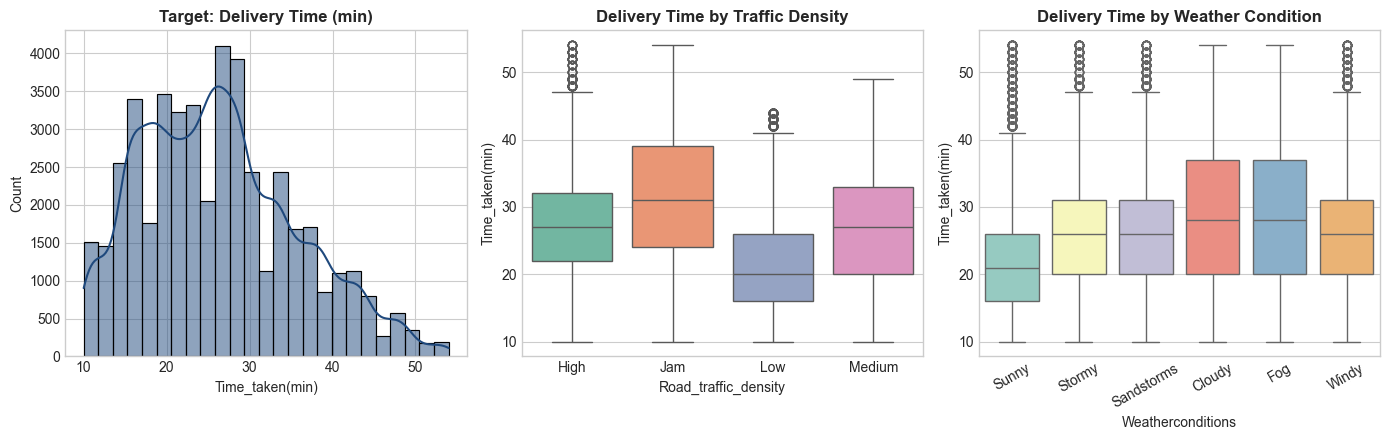

In [14]:
# 3. Exploratory Data Analysis & Visualizations
plt.figure(figsize=(14, 4.5))

plt.subplot(1, 3, 1)
sns.histplot(df_food["Time_taken(min)"], kde=True, color='#1f497d', bins=25)
plt.title("Target: Delivery Time (min)", fontweight='bold')

plt.subplot(1, 3, 2)
sns.boxplot(data=df_food, x="Road_traffic_density", y="Time_taken(min)", palette="Set2")
plt.title("Delivery Time by Traffic Density", fontweight='bold')

plt.subplot(1, 3, 3)
sns.boxplot(data=df_food, x="Weatherconditions", y="Time_taken(min)", palette="Set3")
plt.title("Delivery Time by Weather Condition", fontweight='bold')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


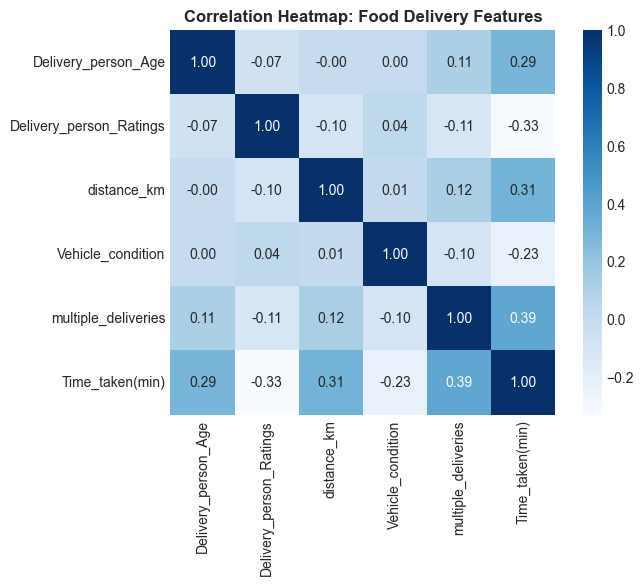

In [15]:
# Correlation Matrix Heatmap
plt.figure(figsize=(7, 5))
num_features = ["Delivery_person_Age", "Delivery_person_Ratings", "distance_km", "Vehicle_condition", "multiple_deliveries", "Time_taken(min)"]
sns.heatmap(df_food[num_features].corr(), annot=True, cmap="Blues", fmt=".2f", square=True)
plt.title("Correlation Heatmap: Food Delivery Features", fontweight='bold')
plt.show()


### 4. Machine Learning Preprocessing Pipeline & Model Comparison
We evaluate five regression algorithms using an 80/20 train/test split.
Preprocessors are strictly encapsulated in a `Pipeline` to eliminate data leakage:
- `StandardScaler` for continuous numerical features.
- `OneHotEncoder(handle_unknown='ignore')` for nominal categorical features.


In [16]:
# Define features and train-test split
num_cols = ["Delivery_person_Age", "Delivery_person_Ratings", "distance_km", "Vehicle_condition", "multiple_deliveries"]
cat_cols = ["Weatherconditions", "Road_traffic_density", "Type_of_vehicle", "Festival", "City"]
target_col = "Time_taken(min)"

X = df_food[num_cols + cat_cols]
y = df_food[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"X_train Shape: {X_train.shape} | X_test Shape: {X_test.shape}")

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
])

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=14, random_state=42, n_jobs=-1)
}

results = []
trained_models = {}

for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("reg", model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    results.append({"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2 Score": r2})
    trained_models[name] = (pipe, y_pred)

comparison_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False).reset_index(drop=True)
print("\nOfficial Regression Model Comparison Table:")
display(comparison_df.round(4))


X_train Shape: (36474, 10) | X_test Shape: (9119, 10)



Official Regression Model Comparison Table:


,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest,3.2240,16.4219,4.0524,0.8127
1,Decision Tree,3.3351,17.9552,4.2374,0.7952
2,Linear Regression,4.7511,35.8277,5.9856,0.5914
3,Ridge Regression,4.7511,35.8280,5.9856,0.5914
4,Lasso Regression,4.7559,35.9044,5.9920,0.5905


C:\Users\HP\AppData\Local\Temp\ipykernel_24280\2325219162.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df, x="Model", y="R2 Score", palette="Blues_r")


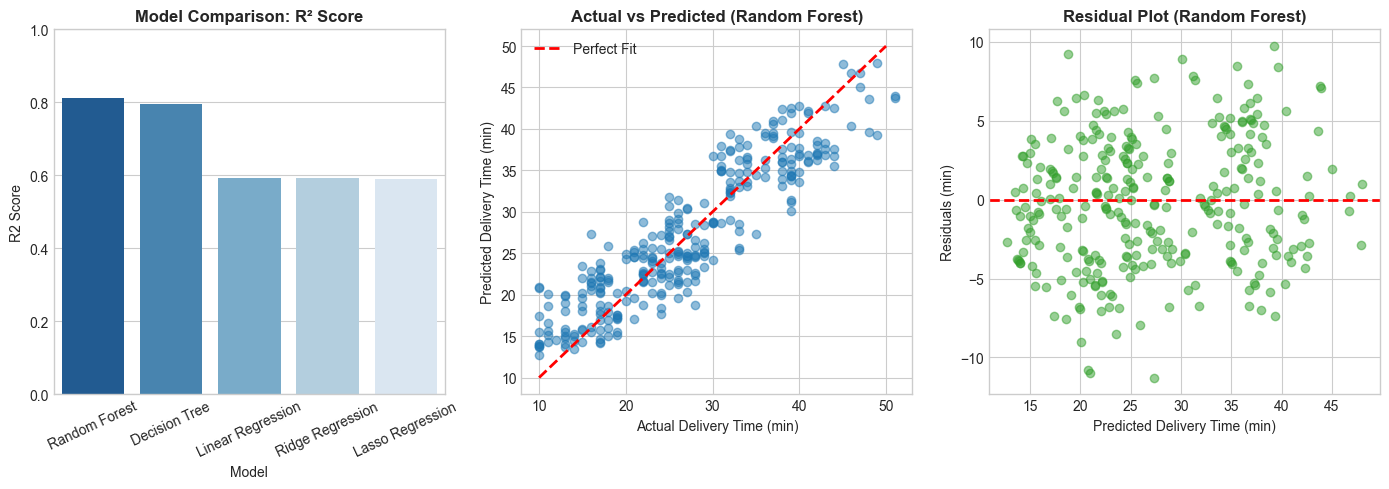

In [17]:
# Model Comparison Visualization & Residual Diagnostics
plt.figure(figsize=(14, 5))

# Model R2 comparison bar chart
plt.subplot(1, 3, 1)
sns.barplot(data=comparison_df, x="Model", y="R2 Score", palette="Blues_r")
plt.title("Model Comparison: R² Score", fontweight='bold')
plt.xticks(rotation=25)
plt.ylim(0, 1.0)

# Actual vs Predicted
best_name = comparison_df.iloc[0]["Model"]
best_pipe, best_preds = trained_models[best_name]

plt.subplot(1, 3, 2)
plt.scatter(y_test[:300], best_preds[:300], alpha=0.5, color="#1f78b4")
plt.plot([10, 50], [10, 50], 'r--', lw=2, label="Perfect Fit")
plt.title(f"Actual vs Predicted ({best_name})", fontweight='bold')
plt.xlabel("Actual Delivery Time (min)")
plt.ylabel("Predicted Delivery Time (min)")
plt.legend()

# Residual Plot
residuals = y_test - best_preds
plt.subplot(1, 3, 3)
plt.scatter(best_preds[:300], residuals[:300], alpha=0.5, color="#33a02c")
plt.axhline(0, color="red", linestyle="--", lw=2)
plt.title(f"Residual Plot ({best_name})", fontweight='bold')
plt.xlabel("Predicted Delivery Time (min)")
plt.ylabel("Residuals (min)")
plt.tight_layout()
plt.show()


### 5. Production Model Deployment & Live Prediction Verification

In [18]:
# Demonstrate sample live prediction using trained pipeline
sample_order = pd.DataFrame([{
    "Delivery_person_Age": 28,
    "Delivery_person_Ratings": 4.8,
    "distance_km": 7.5,
    "Vehicle_condition": 2,
    "multiple_deliveries": 0,
    "Weatherconditions": "Sunny",
    "Road_traffic_density": "Medium",
    "Type_of_vehicle": "motorcycle",
    "Festival": "No",
    "City": "Metropolitian"
}])

pred_delivery_time = best_pipe.predict(sample_order)[0]
print(f"Sample Order Estimated Delivery Time: {pred_delivery_time:.1f} minutes (~{int(round(pred_delivery_time))} mins)")
print("Project pipeline validated and ready for Streamlit deployment!")


Sample Order Estimated Delivery Time: 13.9 minutes (~14 mins)
Project pipeline validated and ready for Streamlit deployment!
